# Réseau XOR Analogique — v4 (MAX SPEED)

Réseau XOR Analogique — v4 (MAX SPEED)

Accélérations vs v3 :
  - layer_forward         : Numba JIT (@njit) — supprime la double boucle Python
  - interp2d_bilinear     : Numba JIT — interpolation compilée
  - network_forward_mc    : CuPy GPU — tirages Monte-Carlo en parallèle sur GPU
  - coordinate_search     : joblib — candidats évalués en parallèle sur N cœurs
  - restarts              : joblib — restarts indépendants en parallèle
  - MIN_MARGIN_HZ = 1kHz  : pénalité dure si marge < 1 kHz (contrainte physique)

Exécuter les cellules dans l'ordre (Kernel → Restart & Run All).
Première exécution plus lente : Numba compile les fonctions JIT au premier appel.

## 0. Imports & Configuration

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys
import time
import warnings
warnings.filterwarnings("ignore")

from numba import njit, prange
import joblib
from tqdm.auto import tqdm, trange
try:
    import cupy as cp
    GPU_AVAILABLE = True
    print("GPU détecté :", cp.cuda.runtime.getDeviceProperties(0)["name"].decode())
except Exception:
    cp = None
    GPU_AVAILABLE = False
    print("GPU non disponible — Monte-Carlo sur CPU.")

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"]  = 11
np.set_printoptions(precision=4, suppress=True)

# ── Fichiers CSV ──────────────────────────────────────────────
INPUT_CSV   = "input_min_conso.csv"
NEURON_CSV  = "neuron.csv"
SYN_EXC_CSV = "excitation20.csv"
SYN_INH_CSV = "inhibition20.csv"

FREQ_MERGE_TOL_HZ = 1000.0

# ── Architecture  [2, N_hidden, 2] ───────────────────────────
HIDDEN_SIZES = [8]   # ex: [4] -> 2-4-2  |  [4,4] -> 2-4-4-2

# ── Recherche ────────────────────────────────────────────────
N_RESTARTS   = 8
MAX_PASSES   = 8
SEED         = 42
N_JOBS       = -1    # -1 = tous les cœurs CPU disponibles

# ── Dataset XOR ──────────────────────────────────────────────
N_TRAIN = 400
N_TEST  = 200
MARGIN  = 0.05

# ── Score avec contrainte physique 1 kHz ─────────────────────
# Plage fréquence hardware : 3 kHz – 193.1 kHz
# On exige au moins 1 kHz d'écart entre F_bonne - F_mauvaise
MARGIN_SCALE       = 1e-4    # 1e-4 × 10kHz ≈ 1.0, même ordre que bal_acc
IMBALANCE_PENALTY  = 0.15
MIN_MARGIN_HZ      = 1000.0  # seuil physique
MIN_MARGIN_PENALTY = 0.5     # pénalité forte si marge < 1 kHz

# ── Robustesse au bruit ───────────────────────────────────────
NOISE_STD_HZ = 500.0   # ~0.5 kHz, conservateur vu plage 3k-193k
N_MC_TRAIN   = 5       # tirages MC pendant coordinate_search
N_MC_EVAL    = 30      # tirages MC pour évaluation finale

print("Configuration OK.")

GPU détecté : NVIDIA GeForce RTX 3080
Configuration OK.


## 1. Fonctions utilitaires

In [15]:
def progress_bar(current, total, prefix="", suffix="", bar_len=35):
    filled = int(bar_len * current / total)
    bar    = "█" * filled + "░" * (bar_len - filled)
    pct    = int(100 * current / total)
    sys.stdout.write("\r  " + prefix + "[" + bar + "] "
                     + str(current) + "/" + str(total)
                     + " (" + str(pct) + "%)  " + suffix)
    sys.stdout.flush()
    if current == total:
        sys.stdout.write("\n")
        sys.stdout.flush()

def read_cadence_rows(csv_path):
    df = pd.read_csv(csv_path)
    if "Parameter" not in df.columns:
        raise ValueError(csv_path + ": colonne 'Parameter' introuvable")
    data_cols = [c for c in df.columns if c not in ["Parameter", "Unnamed: 1"]]
    def get_row(row_name, allow_non_numeric=False):
        row = df.loc[df["Parameter"] == row_name, data_cols]
        if row.empty:
            raise ValueError("Ligne '" + row_name + "' introuvable dans " + csv_path)
        values = pd.to_numeric(row.iloc[0], errors="coerce").to_numpy(dtype=float)
        if not allow_non_numeric and np.isnan(values).any():
            raise ValueError("Ligne '" + row_name + "' contient des NaN")
        return values
    return get_row

def get_clean_rows(reader, row_names):
    rows = [reader(name, allow_non_numeric=True) for name in row_names]
    mask = np.all(np.isfinite(np.vstack(rows)), axis=0)
    return [r[mask] for r in rows], mask

def interp_clip(x, xp, fp):
    return np.interp(np.asarray(x, float), xp, fp, left=fp[0], right=fp[-1])

def strictly_monotonic_branch(x, y):
    idx = int(np.argmax(y))
    xm, ym = np.asarray(x[:idx+1], float), np.asarray(y[:idx+1], float)
    o = np.argsort(xm)
    return xm[o], ym[o]

def merge_close_values(values, tol):
    vals = np.sort(np.asarray(values, float))
    groups = [[vals[0]]]
    for v in vals[1:]:
        if abs(v - np.mean(groups[-1])) <= tol:
            groups[-1].append(v)
        else:
            groups.append([v])
    return np.array([np.mean(g) for g in groups])

def snap_to_axis(values, axis):
    return np.array([axis[np.argmin(np.abs(axis - v))]
                     for v in np.asarray(values, float)])

def build_grid_tolerant(W_all, F_all, Y_all, freq_tol=1000.0):
    W_all, F_all, Y_all = (np.asarray(a, float) for a in (W_all, F_all, Y_all))
    W_unique = np.unique(W_all)
    F_axis   = merge_close_values(np.unique(F_all), tol=freq_tol)
    F_snap   = snap_to_axis(F_all, F_axis)
    z_grid   = np.empty((len(W_unique), len(F_axis)))
    for i, w in enumerate(W_unique):
        for j, f in enumerate(F_axis):
            mask = np.isclose(W_all, w) & np.isclose(F_snap, f)
            if not mask.any():
                raise ValueError("Point manquant W=" + str(w) + " F=" + str(f))
            z_grid[i, j] = np.mean(Y_all[mask])
    return W_unique, F_axis, z_grid

print("Fonctions utilitaires OK.")

Fonctions utilitaires OK.


## 2. Chargement des modèles Cadence

In [16]:
inp = read_cadence_rows(INPUT_CSV)
VEX_IN, FSPIKES_IN = inp("Vex"), inp("Fspikes")
INPUT_V_AXIS, INPUT_F_AXIS = strictly_monotonic_branch(VEX_IN, FSPIKES_IN)

neuro = read_cadence_rows(NEURON_CSV)
IEX_NEURO, FSPIKES_NEURO = neuro("Iex"), neuro("Fspikes")
NEURON_I_AXIS, NEURON_F_AXIS = strictly_monotonic_branch(IEX_NEURO, FSPIKES_NEURO)

syn_exc = read_cadence_rows(SYN_EXC_CSV)
(W2_EXC, FPRE_EXC, IPOST_EXC), _ = get_clean_rows(syn_exc, ["W2", "Fpre", "Ipost"])
W_EXC_AXIS, F_EXC_AXIS, IPOST_EXC_GRID = build_grid_tolerant(
    W2_EXC, FPRE_EXC, IPOST_EXC, FREQ_MERGE_TOL_HZ)

syn_inh = read_cadence_rows(SYN_INH_CSV)
(W2_INH, FPRE_INH, IPOST_INH), _ = get_clean_rows(syn_inh, ["W2", "Fpre", "Ipost"])
W_INH_AXIS, F_INH_AXIS, IPOST_INH_GRID = build_grid_tolerant(
    W2_INH, FPRE_INH, IPOST_INH, FREQ_MERGE_TOL_HZ)

V_MIN       = float(INPUT_V_AXIS[0])
V_MAX       = float(INPUT_V_AXIS[-1])
LAYER_SIZES = [2] + HIDDEN_SIZES + [2]

# Conversion en tableaux C-contiguous float64 pour Numba
_INPUT_V_AXIS   = np.ascontiguousarray(INPUT_V_AXIS,   dtype=np.float64)
_INPUT_F_AXIS   = np.ascontiguousarray(INPUT_F_AXIS,   dtype=np.float64)
_NEURON_I_AXIS  = np.ascontiguousarray(NEURON_I_AXIS,  dtype=np.float64)
_NEURON_F_AXIS  = np.ascontiguousarray(NEURON_F_AXIS,  dtype=np.float64)
_W_EXC_AXIS     = np.ascontiguousarray(W_EXC_AXIS,     dtype=np.float64)
_F_EXC_AXIS     = np.ascontiguousarray(F_EXC_AXIS,     dtype=np.float64)
_IPOST_EXC_GRID = np.ascontiguousarray(IPOST_EXC_GRID, dtype=np.float64)
_W_INH_AXIS     = np.ascontiguousarray(W_INH_AXIS,     dtype=np.float64)
_F_INH_AXIS     = np.ascontiguousarray(F_INH_AXIS,     dtype=np.float64)
_IPOST_INH_GRID = np.ascontiguousarray(IPOST_INH_GRID, dtype=np.float64)
_F_MAX          = float(NEURON_F_AXIS[-1])

print("Input  V : " + str(round(V_MIN*1e3,1)) + " mV -> " + str(round(V_MAX*1e3,1)) + " mV")
print("Neuron I : " + str(round(NEURON_I_AXIS[0]*1e12,1))
      + " pA -> " + str(round(NEURON_I_AXIS[-1]*1e12,1)) + " pA")
print("Exc W (um) : " + str(W_EXC_AXIS))
print("Inh W (um) : " + str(W_INH_AXIS))
print("Architecture : " + str(LAYER_SIZES))

Input  V : -100.0 mV -> 100.0 mV
Neuron I : 3.0 pA -> 1000.0 pA
Exc W (um) : [0.135  0.2858 0.4366 0.5874 0.7382 0.8889 1.04   1.191  1.341  1.492
 1.643  1.794  1.944  2.095  2.246  2.397  2.548  2.698  2.849  3.    ]
Inh W (um) : [0.135  0.1805 0.2261 0.2716 0.3171 0.3626 0.4082 0.4537 0.4992 0.5447
 0.5903 0.6358 0.6813 0.7268 0.7724 0.8179 0.8634 0.9089 0.9545 1.    ]
Architecture : [2, 8, 2]


## 3. Noyaux Numba JIT

In [17]:
# Ces fonctions sont compilées en C au premier appel (~2s), puis très rapides.

@njit(cache=True)
def _interp1d_numba(x, xp, fp):
    """np.interp compilé Numba."""
    if x <= xp[0]:
        return fp[0]
    if x >= xp[-1]:
        return fp[-1]
    lo, hi = 0, len(xp) - 1
    while hi - lo > 1:
        mid = (lo + hi) // 2
        if xp[mid] <= x:
            lo = mid
        else:
            hi = mid
    t = (x - xp[lo]) / (xp[hi] - xp[lo])
    return fp[lo] + t * (fp[hi] - fp[lo])


@njit(cache=True)
def _interp2d_numba(x, y, x_axis, y_axis, z_grid):
    """Interpolation bilinéaire compilée Numba."""
    x = max(x_axis[0], min(x_axis[-1], x))
    y = max(y_axis[0], min(y_axis[-1], y))
    # Recherche dichotomique sur x
    lx, hx = 0, len(x_axis) - 2
    for k in range(len(x_axis) - 1):
        if x_axis[k] <= x < x_axis[k+1]:
            lx = k
            break
    else:
        lx = len(x_axis) - 2
    # Recherche dichotomique sur y
    ly = 0
    for k in range(len(y_axis) - 1):
        if y_axis[k] <= y < y_axis[k+1]:
            ly = k
            break
    else:
        ly = len(y_axis) - 2
    x1, x2 = x_axis[lx], x_axis[lx+1]
    y1, y2 = y_axis[ly], y_axis[ly+1]
    tx = 0.0 if x2 == x1 else (x - x1) / (x2 - x1)
    ty = 0.0 if y2 == y1 else (y - y1) / (y2 - y1)
    return (z_grid[lx,   ly  ] * (1-tx) * (1-ty) +
            z_grid[lx+1, ly  ] * tx     * (1-ty) +
            z_grid[lx,   ly+1] * (1-tx) * ty     +
            z_grid[lx+1, ly+1] * tx     * ty)


@njit(cache=True, parallel=True)
def _layer_forward_numba(Fin, signs_flat, widths_flat, N, M,
                          w_exc, f_exc, g_exc,
                          w_inh, f_inh, g_inh,
                          ni_axis, nf_axis):
    """
    Layer forward entièrement compilé Numba avec parallélisme sur les synapses.
    signs_flat / widths_flat : tableaux 1D de longueur N*M (row-major).
    """
    Iconn = np.zeros(N * M)
    for k in prange(N * M):           # parallélisé sur tous les threads CPU
        i = k // M
        j = k  % M
        s = signs_flat[k]
        w = widths_flat[k]
        f = Fin[i]
        if s == 1:
            Iconn[k] = _interp2d_numba(w, f, w_exc, f_exc, g_exc)
        elif s == -1:
            Iconn[k] = -_interp2d_numba(w, f, w_inh, f_inh, g_inh)

    Itot = np.zeros(M)
    for k in range(N * M):
        j = k % M
        Itot[j] += Iconn[k]

    Fout = np.empty(M)
    for j in range(M):
        Fout[j] = _interp1d_numba(Itot[j], ni_axis, nf_axis)

    return Fout, Iconn.reshape((N, M)), Itot


def layer_forward(Fin_vec_Hz, sign_matrix, width_matrix_um):
    """Wrapper Python de _layer_forward_numba."""
    N, M = sign_matrix.shape
    Fout, Iconn, Itot = _layer_forward_numba(
        np.ascontiguousarray(Fin_vec_Hz, np.float64),
        sign_matrix.ravel().astype(np.float64),
        width_matrix_um.ravel().astype(np.float64),
        N, M,
        _W_EXC_AXIS, _F_EXC_AXIS, _IPOST_EXC_GRID,
        _W_INH_AXIS, _F_INH_AXIS, _IPOST_INH_GRID,
        _NEURON_I_AXIS, _NEURON_F_AXIS
    )
    return Fout, Iconn, Itot


def input_f_of_v(Vin_V):
    return float(_interp1d_numba(float(Vin_V), _INPUT_V_AXIS, _INPUT_F_AXIS))

def neuron_f_of_i(Iin_A):
    return float(_interp1d_numba(float(Iin_A), _NEURON_I_AXIS, _NEURON_F_AXIS))

def isyn_exc(Fpre_Hz, Wexc_um):
    return float(_interp2d_numba(Wexc_um, Fpre_Hz, _W_EXC_AXIS, _F_EXC_AXIS, _IPOST_EXC_GRID))

def isyn_inh(Fpre_Hz, Winh_um):
    return float(_interp2d_numba(Winh_um, Fpre_Hz, _W_INH_AXIS, _F_INH_AXIS, _IPOST_INH_GRID))

# ── Warm-up Numba (déclenche la compilation JIT) ──────────────
print("Compilation Numba JIT (une seule fois)...")
t0 = time.time()
_dummy_signs  = np.array([[1.0, -1.0], [-1.0, 1.0]])
_dummy_widths = np.array([[float(W_EXC_AXIS[0]), float(W_INH_AXIS[0])],
                           [float(W_INH_AXIS[0]), float(W_EXC_AXIS[0])]])
_dummy_F      = np.array([1000.0, 2000.0])
layer_forward(_dummy_F, _dummy_signs, _dummy_widths)
print(f"  JIT compilé en {time.time()-t0:.1f}s — les prochains appels seront rapides.")

print("Noyaux Numba OK.")

Compilation Numba JIT (une seule fois)...
  JIT compilé en 0.0s — les prochains appels seront rapides.
Noyaux Numba OK.


## 4. Propagation CPU + GPU

In [18]:
def network_forward_single(Vin_vec_V, signs, widths):
    """Forward pass déterministe, un seul sample."""
    F = np.array([input_f_of_v(v) for v in Vin_vec_V])
    for sm, wm in zip(signs, widths):
        F, _, _ = layer_forward(F, sm, wm)
    return F

def network_forward_dataset(V_dataset, signs, widths):
    """Forward déterministe sur tout le dataset."""
    return np.array([network_forward_single(Vin, signs, widths) for Vin in V_dataset])


if GPU_AVAILABLE:
    def network_forward_mc(V_dataset, signs, widths, noise_std, n_mc):
        """
        Monte-Carlo sur GPU (CuPy).
        Stratégie : calcule le forward déterministe sur CPU (Numba),
        puis ajoute n_mc réalisations de bruit sur GPU et moyenne.
        """
        N      = len(V_dataset)
        n_out  = LAYER_SIZES[-1]
        # Forward déterministe pour tous les samples — shape (N, n_out)
        Fout_cpu = network_forward_dataset(V_dataset, signs, widths)
        Fout_gpu = cp.asarray(Fout_cpu)           # transfert CPU→GPU
        # Bruit : shape (n_mc, N, n_out)
        noise    = cp.random.normal(0.0, noise_std, (n_mc, N, n_out))
        # Broadcast : ajoute bruit et clamp
        Fout_mc  = cp.clip(Fout_gpu[None, :, :] + noise, 0.0, _F_MAX)
        return cp.asnumpy(Fout_mc.mean(axis=0))   # retour CPU
else:
    def network_forward_mc(V_dataset, signs, widths, noise_std, n_mc):
        """Monte-Carlo CPU fallback."""
        rng = np.random.default_rng()
        acc = np.zeros((len(V_dataset), LAYER_SIZES[-1]))
        for _ in range(n_mc):
            Fout = network_forward_dataset(V_dataset, signs, widths)
            acc += np.clip(Fout + rng.normal(0, noise_std, Fout.shape), 0, _F_MAX)
        return acc / n_mc


print("Propagation OK.")

Propagation OK.


## 5. Dataset XOR

Train : 400 pts  cl1=212  cl0=188
Test  : 200 pts  cl1=110  cl0=90


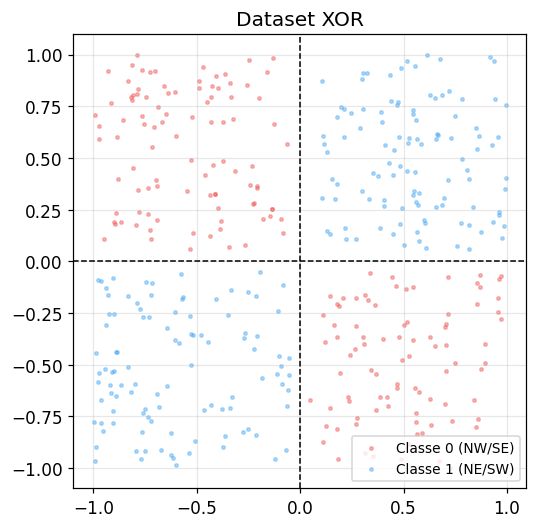

In [19]:
def label_xor(X):
    return (((X[:, 0] > 0) & (X[:, 1] > 0)) |
            ((X[:, 0] < 0) & (X[:, 1] < 0))).astype(int)

def make_dataset(n, seed=0):
    rng = np.random.default_rng(seed)
    pts = []
    while sum(len(p) for p in pts) < n:
        batch = rng.uniform(-1.0, 1.0, size=(n * 2, 2))
        mask  = (np.abs(batch[:, 0]) > MARGIN) & (np.abs(batch[:, 1]) > MARGIN)
        pts.append(batch[mask])
    return np.vstack(pts)[:n], label_xor(np.vstack(pts)[:n])

def xy_to_voltage(X):
    return V_MIN + (np.asarray(X, float) + 1.0) * (V_MAX - V_MIN) / 2.0

X_train, y_train = make_dataset(N_TRAIN, seed=SEED)
X_test,  y_test  = make_dataset(N_TEST,  seed=SEED + 1)
V_train = xy_to_voltage(X_train)
V_test  = xy_to_voltage(X_test)

print("Train : " + str(len(y_train)) + " pts  cl1=" + str(y_train.sum())
      + "  cl0=" + str((1-y_train).sum()))
print("Test  : " + str(len(y_test))  + " pts  cl1=" + str(y_test.sum())
      + "  cl0=" + str((1-y_test).sum()))

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(X_train[y_train==0, 0], X_train[y_train==0, 1],
           s=5, alpha=0.4, c="#EF5350", label="Classe 0 (NW/SE)")
ax.scatter(X_train[y_train==1, 0], X_train[y_train==1, 1],
           s=5, alpha=0.4, c="#42A5F5", label="Classe 1 (NE/SW)")
ax.axhline(0, color="k", lw=1, ls="--")
ax.axvline(0, color="k", lw=1, ls="--")
ax.set_title("Dataset XOR")
ax.set_aspect("equal")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Évaluation avec contrainte 1 kHz

In [20]:
def evaluate_network(V_dataset, y_true, signs, widths,
                     noise_std=0.0, n_mc=1):
    """
    noise_std=0, n_mc=1  ->  déterministe.
    noise_std>0, n_mc>1  ->  Monte-Carlo GPU si disponible.

    Score = bal_acc
            + MARGIN_SCALE * bal_margin          (récompense grande marge)
            - IMBALANCE_PENALTY * |acc0-acc1|    (pénalise déséquilibre classes)
            - MIN_MARGIN_PENALTY * frac_below    (pénalité dure si marge < 1kHz)
    """
    if noise_std > 0 and n_mc > 1:
        Fout = network_forward_mc(V_dataset, signs, widths, noise_std, n_mc)
    else:
        Fout = network_forward_dataset(V_dataset, signs, widths)

    preds = np.argmax(Fout, axis=1)
    y     = np.asarray(y_true, int)
    mask0, mask1 = (y == 0), (y == 1)

    acc0 = float(np.mean(preds[mask0] == 0)) if mask0.any() else 0.0
    acc1 = float(np.mean(preds[mask1] == 1)) if mask1.any() else 0.0
    bal_acc = 0.5 * (acc0 + acc1)

    # Marge signée par point (positive = bonne classification)
    margins = np.where(y == 1,
                       Fout[:, 1] - Fout[:, 0],
                       Fout[:, 0] - Fout[:, 1])
    margin0    = float(np.mean(margins[mask0])) if mask0.any() else 0.0
    margin1    = float(np.mean(margins[mask1])) if mask1.any() else 0.0
    bal_margin = 0.5 * (margin0 + margin1)

    # Fraction de points sous le seuil physique de 1 kHz
    frac_below = float(np.mean(margins < MIN_MARGIN_HZ))

    score = (bal_acc
             + MARGIN_SCALE      * bal_margin
             - IMBALANCE_PENALTY * abs(acc0 - acc1)
             - MIN_MARGIN_PENALTY * frac_below)

    return {"preds": preds, "Fout": Fout,
            "acc0": acc0, "acc1": acc1, "bal_acc": bal_acc,
            "bal_margin": bal_margin, "frac_below": frac_below,
            "score": score}


def print_results(label, m):
    print("\n=== " + label + " ===")
    print("  acc cl0       = " + str(round(m["acc0"], 4)))
    print("  acc cl1       = " + str(round(m["acc1"], 4)))
    print("  bal_acc       = " + str(round(m["bal_acc"], 4)))
    print("  marge moy.    = " + str(round(m["bal_margin"] * 1e-3, 3)) + " kHz")
    print("  pts < 1 kHz   = " + str(round(m["frac_below"] * 100, 1)) + " %")
    print("  score         = " + str(round(m["score"], 6)))


ALL_CANDIDATES = [
    [(+1, float(w)) for w in W_EXC_AXIS] + [(-1, float(w)) for w in W_INH_AXIS]
    for _ in range(len(LAYER_SIZES) - 1)
]
print("Candidats par connexion : " + str(len(ALL_CANDIDATES[0]))
      + " (" + str(len(W_EXC_AXIS)) + " EXC + " + str(len(W_INH_AXIS)) + " INH)")


def random_network(rng):
    signs, widths = [], []
    for li, (n_in, n_out) in enumerate(zip(LAYER_SIZES[:-1], LAYER_SIZES[1:])):
        exc_w = [c[1] for c in ALL_CANDIDATES[li] if c[0] == +1]
        inh_w = [c[1] for c in ALL_CANDIDATES[li] if c[0] == -1]
        s = rng.choice([-1, 1], size=(n_in, n_out))
        w = np.zeros((n_in, n_out))
        for i in range(n_in):
            for j in range(n_out):
                w[i, j] = rng.choice(exc_w if s[i, j] == 1 else inh_w)
        signs.append(s)
        widths.append(w)
    return signs, widths

print("evaluate_network OK.")

Candidats par connexion : 40 (20 EXC + 20 INH)
evaluate_network OK.


## 7. coordinate_search (un seul restart)

In [21]:
def _one_restart(restart_idx, rng_seed, pbar_restarts=None):
    """
    Un restart complet de coordinate search.
    Affichage via print() — compatible Jupyter avec joblib threads.
    """
    rng = np.random.default_rng(rng_seed)
    all_conns = [
        (l, i, j)
        for l, (n_in, n_out) in enumerate(zip(LAYER_SIZES[:-1], LAYER_SIZES[1:]))
        for i in range(n_in)
        for j in range(n_out)
    ]
    n_conns = len(all_conns)

    signs, widths = random_network(rng)
    tr = evaluate_network(V_train, y_train, signs, widths,
                          noise_std=NOISE_STD_HZ, n_mc=N_MC_TRAIN)
    va = evaluate_network(V_test,  y_test,  signs, widths)

    history = [{"pass": 0,
                "tr_bal_acc": tr["bal_acc"], "tr_score": tr["score"],
                "va_bal_acc": va["bal_acc"], "va_score": va["score"]}]
    t0 = time.time()

    R = f"R{restart_idx+1:02d}"
    print(f"  {R} démarré | tr_acc={tr['bal_acc']:.3f} | va_acc={va['bal_acc']:.3f}")

    for pass_idx in range(MAX_PASSES):
        improved   = False
        conn_order = list(all_conns)
        rng.shuffle(conn_order)
        t_pass = time.time()

        for conn_num, (l, i, j) in enumerate(conn_order):
            orig_s = signs[l][i, j]
            orig_w = widths[l][i, j]
            best_s, best_w, best_c = orig_s, orig_w, tr["score"]

            for cs, cw in ALL_CANDIDATES[l]:
                if cs == orig_s and np.isclose(cw, orig_w):
                    continue
                signs[l][i, j]  = cs
                widths[l][i, j] = cw
                ctr = evaluate_network(V_train, y_train, signs, widths,
                                       noise_std=NOISE_STD_HZ, n_mc=N_MC_TRAIN)
                if ctr["score"] > best_c:
                    best_c, best_s, best_w = ctr["score"], cs, cw
                signs[l][i, j]  = orig_s
                widths[l][i, j] = orig_w

            signs[l][i, j]  = best_s
            widths[l][i, j] = best_w
            if best_c > tr["score"]:
                tr       = evaluate_network(V_train, y_train, signs, widths,
                                            noise_std=NOISE_STD_HZ, n_mc=N_MC_TRAIN)
                improved = True

        va = evaluate_network(V_test, y_test, signs, widths)
        history.append({"pass": pass_idx + 1,
                        "tr_bal_acc": tr["bal_acc"], "tr_score": tr["score"],
                        "va_bal_acc": va["bal_acc"], "va_score": va["score"]})

        elapsed_pass = time.time() - t_pass
        status = "converge" if not improved else ""
        print(f"  {R} pass {pass_idx+1}/{MAX_PASSES} | "
              f"tr={tr['bal_acc']:.3f} va={va['bal_acc']:.3f} | "
              f"marge={va['bal_margin']*1e-3:.1f}kHz | "
              f"<1kHz={va['frac_below']*100:.0f}% | "
              f"{elapsed_pass:.0f}s {status}")

        if not improved:
            break

    elapsed = time.time() - t0
    print(f"  ✓ {R} FINI | va_acc={va['bal_acc']:.4f} | "
          f"marge={va['bal_margin']*1e-3:.1f}kHz | "
          f"<1kHz={va['frac_below']*100:.1f}% | {elapsed:.0f}s")

    if pbar_restarts is not None:
        pbar_restarts.update(1)

    return {
        "signs":    [s.copy() for s in signs],
        "widths":   [w.copy() for w in widths],
        "va_score": va["score"],
        "tr_score": tr["score"],
        "history":  history,
    }


def coordinate_search():
    """Lance N_RESTARTS restarts en parallèle via joblib."""
    seeds = [SEED + r * 1000 for r in range(N_RESTARTS)]

    # Une seule barre tqdm — la barre globale des restarts terminés
    pbar_restarts = tqdm(
        total=N_RESTARTS, leave=True,
        desc="Restarts terminés",
        bar_format="{l_bar}{bar}| {n}/{total} [{elapsed}]"
    )

    results = joblib.Parallel(n_jobs=N_JOBS, prefer="threads")(
        joblib.delayed(_one_restart)(r, seeds[r], pbar_restarts)
        for r in range(N_RESTARTS)
    )

    pbar_restarts.close()

    best = max(results, key=lambda r: (r["va_score"], r["tr_score"]))
    print(f"\n★ Meilleur restart : va_score={best['va_score']:.5f}")
    return best["signs"], best["widths"], best["history"]

## 8. Entraînement

In [ ]:
n_conn = sum(LAYER_SIZES[i] * LAYER_SIZES[i+1] for i in range(len(LAYER_SIZES) - 1))
print("Architecture    : " + str(LAYER_SIZES))
print("Restarts        : " + str(N_RESTARTS) + "  (parallèles)")
print("Max passes      : " + str(MAX_PASSES))
print("Connexions      : " + str(n_conn))
print("Candidats/conn  : " + str(len(ALL_CANDIDATES[0])))
print("NOISE_STD_HZ    : " + str(NOISE_STD_HZ) + " Hz")
print("MIN_MARGIN_HZ   : " + str(MIN_MARGIN_HZ) + " Hz")
print("GPU MC          : " + str(GPU_AVAILABLE))

signs, widths, history = coordinate_search()

Architecture    : [2, 8, 2]
Restarts        : 8  (parallèles)
Max passes      : 8
Connexions      : 32
Candidats/conn  : 40
NOISE_STD_HZ    : 500.0 Hz
MIN_MARGIN_HZ   : 1000.0 Hz
GPU MC          : True


Restarts terminés:   0%|          | 0/8 [00:00]

  R02 démarré | tr_acc=0.536 | va_acc=0.500
  R07 démarré | tr_acc=0.486 | va_acc=0.500
  R05 démarré | tr_acc=0.517 | va_acc=0.500
  R08 démarré | tr_acc=0.500 | va_acc=0.500
  R04 démarré | tr_acc=0.488 | va_acc=0.500
  R03 démarré | tr_acc=0.500 | va_acc=0.500
  R01 démarré | tr_acc=0.498 | va_acc=0.500
  R06 démarré | tr_acc=0.444 | va_acc=0.500
  R03 pass 1/8 | tr=0.500 va=0.500 | marge=0.6kHz | <1kHz=55% | 214s 
  R05 pass 1/8 | tr=0.680 va=0.676 | marge=0.5kHz | <1kHz=53% | 215s 
  R06 pass 1/8 | tr=0.688 va=0.703 | marge=0.3kHz | <1kHz=92% | 215s 
  R07 pass 1/8 | tr=0.643 va=0.648 | marge=0.5kHz | <1kHz=73% | 215s 
  R01 pass 1/8 | tr=0.626 va=0.654 | marge=0.5kHz | <1kHz=74% | 216s 
  R04 pass 1/8 | tr=0.553 va=0.565 | marge=0.5kHz | <1kHz=72% | 216s 
  R02 pass 1/8 | tr=0.687 va=0.648 | marge=0.4kHz | <1kHz=74% | 216s 
  R08 pass 1/8 | tr=0.500 va=0.500 | marge=0.9kHz | <1kHz=55% | 216s 
  R05 pass 2/8 | tr=0.687 va=0.690 | marge=0.4kHz | <1kHz=50% | 217s 
  R07 pass 2/8 | t

## 9. Résultats


=== TRAIN (déterministe) ===
  acc cl0       = 0.4574
  acc cl1       = 0.8113
  bal_acc       = 0.6344
  marge moy.    = 0.273 kHz
  pts < 1 kHz   = 44.0 %
  score         = 0.388633

=== TEST  (déterministe) ===
  acc cl0       = 0.5111
  acc cl1       = 0.8364
  bal_acc       = 0.6737
  marge moy.    = 0.661 kHz
  pts < 1 kHz   = 41.0 %
  score         = 0.486076

=== TRAIN (robuste MC) ===
  acc cl0       = 0.4574
  acc cl1       = 0.8113
  bal_acc       = 0.6344
  marge moy.    = 0.272 kHz
  pts < 1 kHz   = 43.8 %
  score         = 0.3898

=== TEST  (robuste MC) ===
  acc cl0       = 0.5111
  acc cl1       = 0.8364
  bal_acc       = 0.6737
  marge moy.    = 0.664 kHz
  pts < 1 kHz   = 40.0 %
  score         = 0.491309


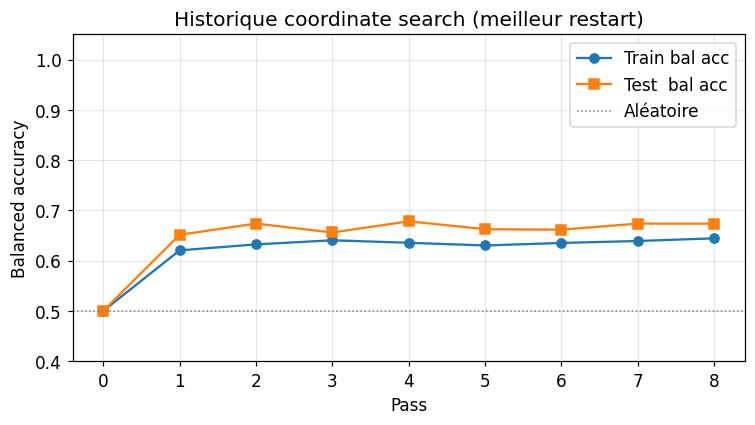

In [ ]:
m_train = evaluate_network(V_train, y_train, signs, widths)
m_test  = evaluate_network(V_test,  y_test,  signs, widths)
print_results("TRAIN (déterministe)", m_train)
print_results("TEST  (déterministe)", m_test)

m_train_rob = evaluate_network(V_train, y_train, signs, widths,
                                noise_std=NOISE_STD_HZ, n_mc=N_MC_EVAL)
m_test_rob  = evaluate_network(V_test,  y_test,  signs, widths,
                                noise_std=NOISE_STD_HZ, n_mc=N_MC_EVAL)
print_results("TRAIN (robuste MC)", m_train_rob)
print_results("TEST  (robuste MC)", m_test_rob)

if history:
    passes = [h["pass"] for h in history]
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(passes, [h["tr_bal_acc"] for h in history], "o-", label="Train bal acc")
    ax.plot(passes, [h["va_bal_acc"] for h in history], "s-", label="Test  bal acc")
    ax.axhline(0.5, color="gray", ls=":", lw=1, label="Aléatoire")
    ax.set_xlabel("Pass")
    ax.set_ylabel("Balanced accuracy")
    ax.set_title("Historique coordinate search (meilleur restart)")
    ax.set_ylim(0.4, 1.05)
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## 10. Carte de décision

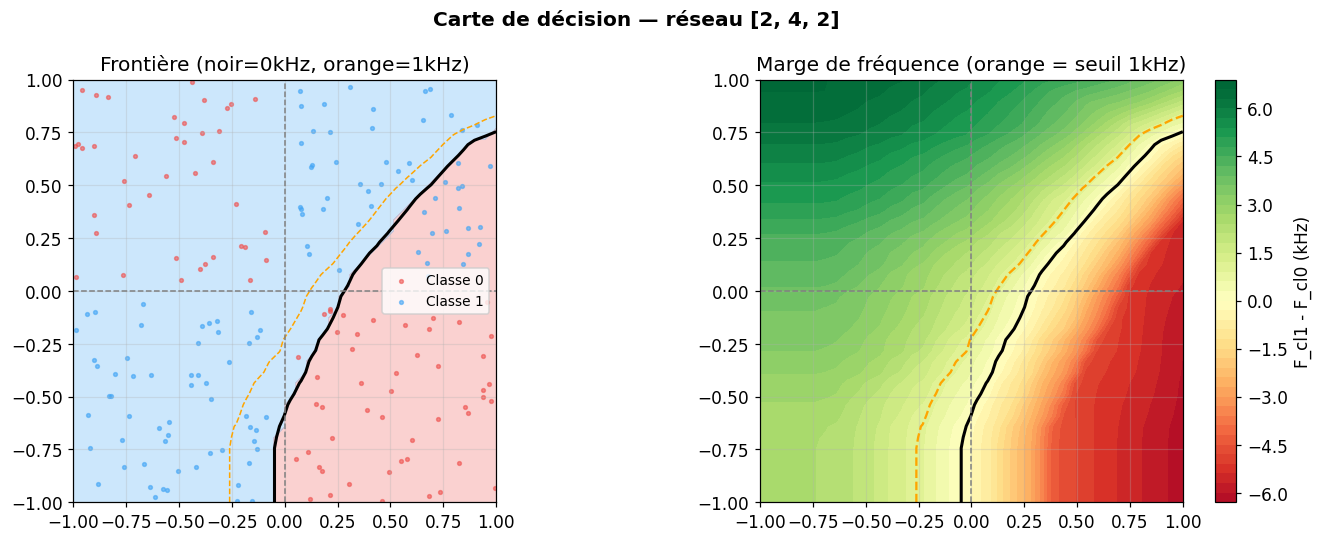

In [ ]:
resolution = 40
xs = np.linspace(-1, 1, resolution)
ys = np.linspace(-1, 1, resolution)
XX, YY = np.meshgrid(xs, ys)
grid_V = xy_to_voltage(np.column_stack([XX.ravel(), YY.ravel()]))

Fout_grid   = network_forward_dataset(grid_V, signs, widths)
pred_grid   = np.argmax(Fout_grid, axis=1).reshape(XX.shape)
margin_grid = (Fout_grid[:, 1] - Fout_grid[:, 0]).reshape(XX.shape) * 1e-3

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Carte de décision — réseau " + str(LAYER_SIZES), fontweight="bold")

ax = axes[0]
ax.contourf(XX, YY, pred_grid, levels=[-0.5, 0.5, 1.5],
            colors=["#EF535044", "#42A5F544"])
ax.contour(XX, YY, margin_grid, levels=[0], colors="k", linewidths=2)
ax.contour(XX, YY, margin_grid, levels=[1.0], colors="orange",
           linewidths=1, linestyles="--")  # iso-contour 1 kHz
ax.scatter(X_test[y_test==0, 0], X_test[y_test==0, 1],
           s=6, c="#EF5350", alpha=0.6, label="Classe 0")
ax.scatter(X_test[y_test==1, 0], X_test[y_test==1, 1],
           s=6, c="#42A5F5", alpha=0.6, label="Classe 1")
ax.axhline(0, color="gray", lw=1, ls="--")
ax.axvline(0, color="gray", lw=1, ls="--")
ax.set_title("Frontière (noir=0kHz, orange=1kHz)")
ax.set_aspect("equal")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

ax = axes[1]
vmax = max(abs(float(margin_grid.min())), abs(float(margin_grid.max())), 1.0)
cf = ax.contourf(XX, YY, margin_grid, levels=50, cmap="RdYlGn", vmin=-vmax, vmax=vmax)
plt.colorbar(cf, ax=ax, label="F_cl1 - F_cl0 (kHz)")
ax.contour(XX, YY, margin_grid, levels=[0], colors="k", linewidths=2)
ax.contour(XX, YY, margin_grid, levels=[1.0], colors="orange",
           linewidths=1.5, linestyles="--")
ax.axhline(0, color="gray", lw=1, ls="--")
ax.axvline(0, color="gray", lw=1, ls="--")
ax.set_title("Marge de fréquence (orange = seuil 1kHz)")
ax.set_aspect("equal")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 11. Diagnostic Cadence — plages de courant

In [ ]:
print("=" * 60)
print("  DIAGNOSTIC — Itot par couche vs plage neurone")
print("  Plage neurone : ["
      + str(round(NEURON_I_AXIS[0]*1e12, 1)) + " pA, "
      + str(round(NEURON_I_AXIS[-1]*1e12, 1)) + " pA]")
print("=" * 60)

all_itot = [[] for _ in range(len(LAYER_SIZES) - 1)]
for Vin in V_train:
    F = np.array([input_f_of_v(v) for v in Vin])
    for li, (sm, wm) in enumerate(zip(signs, widths)):
        F, _, Itot = layer_forward(F, sm, wm)
        all_itot[li].extend(Itot.tolist())

n_lo = NEURON_I_AXIS[0]
n_hi = NEURON_I_AXIS[-1]
for li, itots in enumerate(all_itot):
    itots  = np.array(itots)
    lo, hi = itots.min(), itots.max()
    pct    = 100 * np.mean((itots >= n_lo) & (itots <= n_hi))
    status = "OK" if pct == 100 else f"ATTENTION {100-pct:.1f}% hors plage"
    print(f"  Couche {li}: Itot in [{lo*1e12:.1f}, {hi*1e12:.1f}] pA  -> {status}")

print("=" * 60)
print("Courants hors plage = saturation sur Cadence.")

  DIAGNOSTIC — Itot par couche vs plage neurone
  Plage neurone : [3.0 pA, 1000.0 pA]
  Couche 0: Itot in [-24.8, 909.5] pA  -> ATTENTION 28.2% hors plage
  Couche 1: Itot in [719.5, 1001.2] pA  -> ATTENTION 0.1% hors plage
Courants hors plage = saturation sur Cadence.


## 12. Export des poids pour Cadence

In [ ]:
layer_names = (["In->H1"]
               + ["H" + str(k) + "->H" + str(k+1) for k in range(1, len(signs) - 1)]
               + ["H" + str(len(signs) - 1) + "->Out"])

print("\n=== POIDS FINAUX réseau " + str(LAYER_SIZES) + " ===")
for k, (s, w, ln) in enumerate(zip(signs, widths, layer_names)):
    print(f"\n  Couche {k+1} [{ln}]  {s.shape[0]}->{s.shape[1]}")
    print("    Signes :\n" + str(s))
    print("    Largeurs (um) :\n" + str(w))
    print("    EXC=" + str(int((s == +1).sum()))
          + "  INH=" + str(int((s == -1).sum())))

rows = []
for li, (s, w) in enumerate(zip(signs, widths)):
    n_in, n_out = s.shape
    for i in range(n_in):
        for j in range(n_out):
            rows.append({
                "layer":    li + 1,
                "pre":      i,
                "post":     j,
                "sign":     int(s[i, j]),
                "width_um": float(w[i, j]),
                "type":     "EXC" if s[i, j] == 1 else "INH"
            })

df_weights = pd.DataFrame(rows)
df_weights.to_csv("weights_cadence.csv", index=False)
print("\nweights_cadence.csv généré :")
print(df_weights.to_string(index=False))


=== POIDS FINAUX réseau [2, 4, 2] ===

  Couche 1 [In->H1]  2->4
    Signes :
[[-1  1  1 -1]
 [ 1  1  1 -1]]
    Largeurs (um) :
[[0.2716 0.4366 1.794  1.    ]
 [0.135  2.849  3.     0.1805]]
    EXC=5  INH=3

  Couche 2 [H1->Out]  4->2
    Signes :
[[-1  1]
 [ 1  1]
 [ 1 -1]
 [-1 -1]]
    Largeurs (um) :
[[0.3171 2.698 ]
 [0.4366 1.643 ]
 [1.643  0.4537]
 [0.2716 0.2261]]
    EXC=4  INH=4

weights_cadence.csv généré :
 layer  pre  post  sign  width_um type
     1    0     0    -1    0.2716  INH
     1    0     1     1    0.4366  EXC
     1    0     2     1    1.7940  EXC
     1    0     3    -1    1.0000  INH
     1    1     0     1    0.1350  EXC
     1    1     1     1    2.8490  EXC
     1    1     2     1    3.0000  EXC
     1    1     3    -1    0.1805  INH
     2    0     0    -1    0.3171  INH
     2    0     1     1    2.6980  EXC
     2    1     0     1    0.4366  EXC
     2    1     1     1    1.6430  EXC
     2    2     0     1    1.6430  EXC
     2    2     1    -1    0.4